# SMART VINEYARD
## 03. TIỀN XỬ LÝ ẢNH & CHUẨN BỊ DỮ LIỆU (IMAGE PREPROCESSING)

### 1. Mục tiêu
- Đọc dữ liệu đã ghép từ bước `02_DataMatching` (`image_metadata.json`).
- Băm MD5 toàn bộ ảnh để định danh các nhóm ảnh trùng lặp và kiểm tra tính nhất quán của nhãn.
- Loại bỏ hoàn toàn các nhóm ảnh bị mâu thuẫn nhãn (cùng 1 bức ảnh nhưng gán nhiều loại bệnh khác nhau).
- **Tách luồng dữ liệu chuẩn cho 2 bài toán**:
  - **Bài toán 1 (Phân loại bệnh qua ảnh lá nho)**: Khử trùng tuyệt đối (mỗi mã MD5 giữ 1 ảnh đại diện), đánh giá chất lượng thị giác (Độ sáng, Độ tương phản, Độ mờ Laplacian, thống kê kênh màu RGB), trích xuất đặc trưng bàn tay (Màu sắc HSV, Kết cấu GLCM, Hình dạng Hu Moments) và chia tập Train/Val/Test (70/15/15) đảm bảo không rò rỉ dữ liệu (Zero Data Leakage).
  - **Bài toán 2 (Phân tích phân bố bệnh & môi trường)**: Xuất bộ dữ liệu nhất quán (`task2_env_full_3472.csv`) và bộ dữ liệu đối chứng đã khử trùng (`task2_env_dedup_2405.csv`) phục vụ gom cụm vườn nho và khai phá luật kết hợp.

### 2. Import thư viện & Cấu hình đường dẫn

In [1]:
import json
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
RANDOM_STATE = 42

# Cấu hình đường dẫn đồng bộ với 02_DataMatching
PROJECT_DIR = Path(r"D:\DataMining26\Smart-Vineyard")
DATASET_DIR = (
    PROJECT_DIR
    / "Dataset"
    / "GVLID Grapevine Leaf identification of the Disease"
    / "DATASET"
)
PROCESSED_DIR = PROJECT_DIR / "outputs" / "processed"
MATCHED_JSON = PROCESSED_DIR / "image_metadata.json"

# Thư mục lưu kết quả đầu ra của bước 03
STEP03_DIR = PROCESSED_DIR / "step03_clean"
STEP03_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset tồn tại      :", DATASET_DIR.exists())
print("Matched JSON tồn tại :", MATCHED_JSON.exists())
print("Thư mục lưu bước 03  :", STEP03_DIR)

Dataset tồn tại      : True
Matched JSON tồn tại : True
Thư mục lưu bước 03  : D:\DataMining26\Smart-Vineyard\outputs\processed\step03_clean


### 3. Đọc dữ liệu ghép & Định danh nhóm ảnh trùng bằng MD5
Tính toán mã băm MD5 trên nội dung nhị phân của từng tệp ảnh để gom nhóm các ảnh giống hệt nhau và kiểm tra xem có nhóm ảnh nào bị gán nhiều nhãn bệnh khác nhau không.

In [2]:
with open(MATCHED_JSON, "r", encoding="utf-8") as f:
    df = pd.DataFrame(json.load(f))

def compute_md5(rel_path, chunk=1 << 20):
    full_path = DATASET_DIR / rel_path
    h = hashlib.md5()
    with open(full_path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

df["MD5"] = df["Image_Path"].apply(compute_md5)

# Thống kê kích thước nhóm trùng và số nhãn bệnh trong mỗi nhóm MD5
md5_stats = df.groupby("MD5").agg(
    Group_Size=("Sr_No", "count"),
    Num_Classes=("Disease_Type", "nunique")
).reset_index()

# Gán mã định danh nhóm (Dup_Group_Id) dễ theo dõi
md5_stats = md5_stats.sort_values(["Group_Size", "MD5"], ascending=[False, True]).reset_index(drop=True)
md5_stats["Dup_Group_Id"] = [f"GRP_{i+1:04d}" for i in range(len(md5_stats))]

df = df.merge(md5_stats, on="MD5", how="left")

print(f"Tổng số bản ghi đầu vào                           : {len(df)}")
print(f"Số lượng ảnh độc nhất (MD5 duy nhất)             : {df['MD5'].nunique()}")
print(f"Số nhóm có >= 2 ảnh trùng nhau                   : {(md5_stats['Group_Size'] > 1).sum()}")
print(f"Số nhóm bị mâu thuẫn nhãn (Num_Classes > 1)      : {(md5_stats['Num_Classes'] > 1).sum()}")

Tổng số bản ghi đầu vào                           : 3476
Số lượng ảnh độc nhất (MD5 duy nhất)             : 2409
Số nhóm có >= 2 ảnh trùng nhau                   : 446
Số nhóm bị mâu thuẫn nhãn (Num_Classes > 1)      : 2


### 4. Xử lý mâu thuẫn nhãn & Khử trùng dữ liệu (Deduplication)
- **Nhóm mâu thuẫn nhãn (`Num_Classes > 1`)**: Cùng một bức ảnh nhưng nằm ở 2 thư mục bệnh khác nhau $\rightarrow$ Loại bỏ hoàn toàn để tránh nhiễu nhãn.
- **Nhóm trùng cùng lớp (`Num_Classes == 1` và `Group_Size > 1`)**: Giữ lại 1 ảnh đại diện đầu tiên (`keep="first"`) cho Bài toán 1 để ngăn chặn học vẹt (Overfitting) và rò rỉ dữ liệu giữa tập Train và Test.

In [3]:
# 1. Tách và kiểm tra các bản ghi bị mâu thuẫn nhãn
df_conflict = df[df["Num_Classes"] > 1].sort_values(["Dup_Group_Id", "Sr_No"]).copy()
print(f"Số bản ghi bị loại do mâu thuẫn nhãn: {len(df_conflict)}")
display(df_conflict[["Dup_Group_Id", "Sr_No", "Image_Name", "Disease_Type", "Location.Vineyard", "MD5"]])

# 2. Tập dữ liệu nhất quán (Consistent Dataset - dùng cho Bài toán 2 Full)
df_consistent = df[df["Num_Classes"] == 1].sort_values(["Disease_Type", "Image_Number"]).reset_index(drop=True)
print(f"Số bản ghi nhất quán còn lại (Bài 2 - Full): {len(df_consistent)}")

# 3. Tập dữ liệu ảnh độc nhất (Unique Dataset - dùng cho Bài toán 1 & Bài toán 2 Đối chứng)
df_task1 = df_consistent.drop_duplicates(subset=["MD5"], keep="first").reset_index(drop=True)
print(f"Số ảnh độc nhất sau khi khử trùng (Bài 1 - Unique): {len(df_task1)}")

# Bảng đối chiếu phân bố lớp trước và sau khi khử trùng
compare_dist = pd.concat([
    df["Disease_Type"].value_counts().rename("Ban_dau (3476)"),
    df_consistent["Disease_Type"].value_counts().rename("Bo_mau_thuan (3472)"),
    df_task1["Disease_Type"].value_counts().rename("Sau_khu_trung (2405)"),
    (df_task1["Disease_Type"].value_counts(normalize=True) * 100).round(2).rename("Ty_le_Unique (%)")
], axis=1)
display(compare_dist)

Số bản ghi bị loại do mâu thuẫn nhãn: 18


,Dup_Group_Id,Sr_No,Image_Name,Disease_Type,Location.Vineyard,MD5
791,GRP_0003,793,black rot793.jpg,Black Rot,Vineyard_18,008bb3e396058405013d3402a4b20561
792,GRP_0003,794,black rot794.jpg,Black Rot,Vineyard_16,008bb3e396058405013d3402a4b20561
793,GRP_0003,795,black rot795.jpg,Black Rot,Vineyard_17,008bb3e396058405013d3402a4b20561
794,GRP_0003,796,black rot796.jpg,Black Rot,Vineyard_4,008bb3e396058405013d3402a4b20561
795,GRP_0003,797,black rot797.jpg,Black Rot,Vineyard_20,008bb3e396058405013d3402a4b20561
796,GRP_0003,798,black rot798.jpg,Black Rot,Vineyard_6,008bb3e396058405013d3402a4b20561
797,GRP_0003,799,black rot799.jpg,Black Rot,Vineyard_12,008bb3e396058405013d3402a4b20561
798,GRP_0003,800,black rot800.jpg,Black Rot,Vineyard_28,008bb3e396058405013d3402a4b20561
808,GRP_0003,811,esca002.jpg,Esca,Vineyard_6,008bb3e396058405013d3402a4b20561
799,GRP_0004,801,black rot801.jpg,Black Rot,Vineyard_7,cdcf88c8e785c459d26520de92f6817d


Số bản ghi nhất quán còn lại (Bài 2 - Full): 3458
Số ảnh độc nhất sau khi khử trùng (Bài 1 - Unique): 2407


,Ban_dau (3476),Bo_mau_thuan (3472),Sau_khu_trung (2405),Ty_le_Unique (%)
Disease_Type,,,,
Healthy,1109,1109,1093,45.41
Esca,888,886,886,36.81
Black Rot,807,791,97,4.03
Leaf Blight,672,672,331,13.75


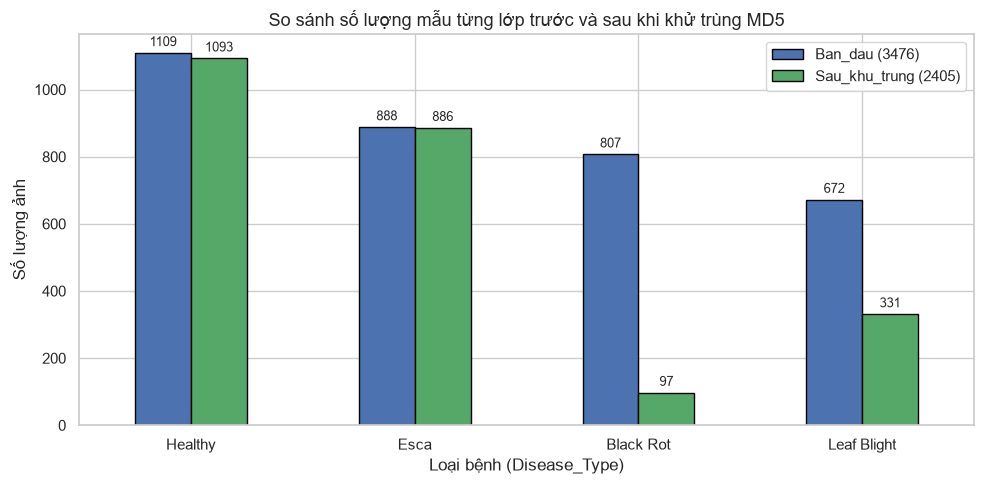

In [4]:
# Trực quan hóa phân bố nhãn trước và sau khi khử trùng
ax = compare_dist[["Ban_dau (3476)", "Sau_khu_trung (2405)"]].plot(
    kind="bar", figsize=(10, 5), color=["#4C72B0", "#55A868"], edgecolor="black"
)
plt.title("So sánh số lượng mẫu từng lớp trước và sau khi khử trùng MD5", fontsize=13)
plt.xlabel("Loại bệnh (Disease_Type)")
plt.ylabel("Số lượng ảnh")
plt.xticks(rotation=0)
for container in ax.containers:
    ax.bar_label(container, fontsize=9, padding=3)
plt.tight_layout()
plt.show()

### 5. Đánh giá chất lượng thị giác & Thống kê kênh màu RGB
Kiểm tra các chỉ số thị giác trên tập ảnh độc nhất (`df_task1`):
- **Độ sáng (`Brightness`)**: Trung bình cường độ sáng mức xám.
- **Độ tương phản (`Contrast`)**: Độ lệch chuẩn cường độ mức xám.
- **Độ sắc nét (`Blur_Laplacian`)**: Phương sai của toán tử Laplacian (giá trị quá thấp báo hiệu ảnh bị mờ/out nét).
- **Mean / Std kênh RGB**: Thông số chuẩn hóa (`Normalize`) đầu vào cho các mô hình Deep Learning.

In [5]:
def extract_image_quality(rel_path):
    full_path = DATASET_DIR / rel_path
    # Sử dụng np.fromfile + cv2.imdecode để đọc an toàn mọi đường dẫn có khoảng trắng/tiếng Việt
    img_bytes = np.fromfile(str(full_path), dtype=np.uint8)
    img_bgr = cv2.imdecode(img_bytes, cv2.IMREAD_COLOR)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB) / 255.0

    brightness = float(np.mean(img_gray))
    contrast = float(np.std(img_gray))
    blur_laplacian = float(cv2.Laplacian(img_gray, cv2.CV_64F).var())

    r_mean, g_mean, b_mean = np.mean(img_rgb, axis=(0, 1))
    r_std, g_std, b_std = np.std(img_rgb, axis=(0, 1))

    return pd.Series(
        [brightness, contrast, blur_laplacian, r_mean, g_mean, b_mean, r_std, g_std, b_std],
        index=["Brightness", "Contrast", "Blur_Laplacian", "R_mean", "G_mean", "B_mean", "R_std", "G_std", "B_std"]
    )

print("Đang tính toán chỉ số chất lượng ảnh trên tập ảnh độc nhất...")
quality_df = df_task1["Image_Path"].apply(extract_image_quality)
df_task1 = pd.concat([df_task1, quality_df], axis=1)

rgb_mean = df_task1[["R_mean", "G_mean", "B_mean"]].mean().round(4).tolist()
rgb_std = df_task1[["R_std", "G_std", "B_std"]].mean().round(4).tolist()

print(f"Thông số chuẩn hóa RGB (0..1) -> Mean: {rgb_mean} | Std: {rgb_std}")
display(df_task1[["Brightness", "Contrast", "Blur_Laplacian", "R_mean", "G_mean", "B_mean"]].describe().round(2))

Đang tính toán chỉ số chất lượng ảnh trên tập ảnh độc nhất...
Thông số chuẩn hóa RGB (0..1) -> Mean: [0.4658, 0.4949, 0.2657] | Std: [0.2295, 0.2314, 0.1882]


,Brightness,Contrast,Blur_Laplacian,R_mean,G_mean,B_mean
count,2407.00,2407.00,2407.00,2407.00,2407.00,2407.00
mean,117.31,55.89,255.00,0.47,0.49,0.27
std,18.28,10.40,251.20,0.08,0.08,0.09
min,52.02,21.00,3.82,0.20,0.22,0.08
25%,104.88,47.95,91.52,0.41,0.45,0.20
50%,116.79,57.72,207.53,0.46,0.49,0.25
75%,129.16,64.22,337.77,0.52,0.54,0.32
max,180.56,94.50,4804.54,0.72,0.78,0.60


C:\Users\Khang Nguyen\AppData\Local\Temp\ipykernel_12536\1708875357.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_task1, x="Disease_Type", y=col, ax=ax, palette="Set2")
C:\Users\Khang Nguyen\AppData\Local\Temp\ipykernel_12536\1708875357.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_task1, x="Disease_Type", y=col, ax=ax, palette="Set2")
C:\Users\Khang Nguyen\AppData\Local\Temp\ipykernel_12536\1708875357.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_task1, x="Disease_Type", y=col, ax=ax, palette="Set2"

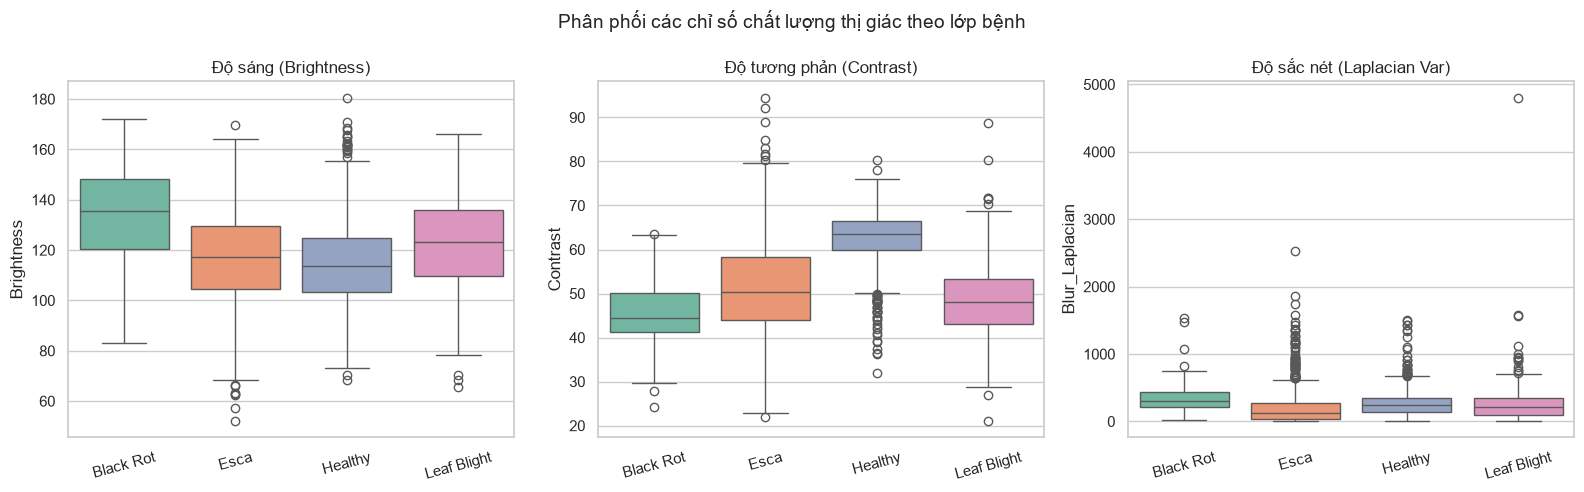

In [6]:
# Biểu đồ phân phối Độ sáng, Độ tương phản và Độ sắc nét theo từng loại bệnh
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metrics = [("Brightness", "Độ sáng (Brightness)"), ("Contrast", "Độ tương phản (Contrast)"), ("Blur_Laplacian", "Độ sắc nét (Laplacian Var)")]

for ax, (col, title) in zip(axes, metrics):
    sns.boxplot(data=df_task1, x="Disease_Type", y=col, ax=ax, palette="Set2")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)

plt.suptitle("Phân phối các chỉ số chất lượng thị giác theo lớp bệnh", fontsize=14)
plt.tight_layout()
plt.show()

### 6. Chia tập dữ liệu Train / Val / Test (70% / 15% / 15%) & Tính Class Weights
Thực hiện chia phân tầng (`Stratified Split`) trên tập ảnh độc nhất (`df_task1`), đảm bảo:
1. Tỷ lệ các lớp bệnh đồng đều giữa 3 tập Train, Validation và Test.
2. Không có bất kỳ mã MD5 nào xuất hiện ở cả 2 tập (Zero Data Leakage).

In [7]:
train_idx, temp_idx = train_test_split(
    df_task1.index,
    test_size=0.30,
    stratify=df_task1["Disease_Type"],
    random_state=RANDOM_STATE
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=df_task1.loc[temp_idx, "Disease_Type"],
    random_state=RANDOM_STATE
)

df_task1["Split"] = "train"
df_task1.loc[val_idx, "Split"] = "val"
df_task1.loc[test_idx, "Split"] = "test"

# Kiểm chứng không rò rỉ ảnh trùng giữa các tập
md5_train = set(df_task1.loc[df_task1["Split"] == "train", "MD5"])
md5_val   = set(df_task1.loc[df_task1["Split"] == "val", "MD5"])
md5_test  = set(df_task1.loc[df_task1["Split"] == "test", "MD5"])
assert len(md5_train & md5_val) == 0 and len(md5_train & md5_test) == 0 and len(md5_val & md5_test) == 0
print("Kiểm tra Data Leakage: 0 ảnh trùng lặp giữa Train, Val và Test!")

# Thống kê số lượng và tỷ lệ phần trăm từng tập
split_counts = pd.crosstab(df_task1["Split"], df_task1["Disease_Type"]).loc[["train", "val", "test"]]
split_pct = (split_counts.div(split_counts.sum(axis=1), axis=0) * 100).round(2)
split_summary = pd.concat([split_counts, split_pct], axis=1, keys=["So_luong", "Ty_le (%)"])
display(split_summary)

# Tính Class Weights trên tập Train đã khử trùng
y_train = df_task1.loc[df_task1["Split"] == "train", "Disease_Type"]
classes = np.sort(y_train.unique())
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights_dict = {c: round(float(w), 4) for c, w in zip(classes, weights)}
print("Class Weights trên tập Train (Unique):", class_weights_dict)

Kiểm tra Data Leakage: 0 ảnh trùng lặp giữa Train, Val và Test!


So_luong                          Ty_le (%)                 \
Disease_Type Black Rot Esca Healthy Leaf Blight Black Rot   Esca Healthy   
Split                                                                      
train               68  620     765         231      4.04  36.82   45.43   
val                 14  133     164          50      3.88  36.84   45.43   
test                15  133     164          50      4.14  36.74   45.30   

                          
Disease_Type Leaf Blight  
Split                     
train              13.72  
val                13.85  
test               13.81

Class Weights trên tập Train (Unique): {'Black Rot': 6.1912, 'Esca': 0.679, 'Healthy': 0.5503, 'Leaf Blight': 1.8225}


### 7. Trích xuất đặc trưng ảnh dạng bảng (Handcrafted Features cho Data Mining)
Để phục vụ các mô hình Khai phá dữ liệu và Học máy cổ điển (SVM, Random Forest, XGBoost, KNN) trong Bài toán 1, mỗi bức ảnh được chuẩn hóa về kích thước `256x256` và trích xuất **28 đặc trưng thị giác**:
- **9 đặc trưng Màu sắc (Không gian màu HSV)**: Mean, Std, Skewness của 3 kênh Hue, Saturation, Value.
- **12 đặc trưng Kết cấu bề mặt lá (GLCM - Gray-Level Co-occurrence Matrix)**: Mean và Std của Contrast, Dissimilarity, Homogeneity, Energy, Correlation, ASM.
- **7 đặc trưng Hình dạng (Hu Moments)**: 7 bất biến moment hình học đã biến đổi logarit.

In [8]:
try:
    from skimage.feature import graycomatrix, graycoprops
except ImportError:
    from skimage.feature.texture import greycomatrix as graycomatrix, greycoprops as graycoprops

def extract_handcrafted_features(rel_path, resize_dim=(256, 256)):
    full_path = DATASET_DIR / rel_path
    img_bytes = np.fromfile(str(full_path), dtype=np.uint8)
    img_bgr = cv2.imdecode(img_bytes, cv2.IMREAD_COLOR)
    img_bgr = cv2.resize(img_bgr, resize_dim, interpolation=cv2.INTER_AREA)

    # 1. Đặc trưng Màu sắc (HSV: Mean, Std, Skewness)
    img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    color_feats = []
    for i in range(3):
        ch = img_hsv[:, :, i].astype(np.float32)
        mean = float(np.mean(ch))
        std = float(np.std(ch))
        skew = float(np.mean(((ch - mean) / (std + 1e-6)) ** 3))
        color_feats.extend([mean, std, skew])

    # 2. Đặc trưng Kết cấu (GLCM trên ảnh mức xám)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    glcm = graycomatrix(
        img_gray,
        distances=[1, 3],
        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
        levels=256,
        symmetric=True,
        normed=True
    )
    texture_feats = []
    glcm_props = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
    for prop in glcm_props:
        vals = graycoprops(glcm, prop)
        texture_feats.append(float(np.mean(vals)))
        texture_feats.append(float(np.std(vals)))

    # 3. Đặc trưng Hình dạng (7 Hu Moments)
    moments = cv2.moments(img_gray)
    hu = cv2.HuMoments(moments).flatten()
    hu_feats = [float(-np.sign(h) * np.log10(np.abs(h) + 1e-12)) for h in hu]

    feat_names = (
        [f"HSV_{c}_{s}" for c in ["H", "S", "V"] for s in ["mean", "std", "skew"]]
        + [f"GLCM_{p}_{s}" for p in glcm_props for s in ["mean", "std"]]
        + [f"HuMoment_{i+1}" for i in range(7)]
    )
    return pd.Series(color_feats + texture_feats + hu_feats, index=feat_names)

print("Đang trích xuất 28 đặc trưng Màu sắc (HSV) + Kết cấu (GLCM) + Hình dạng (Hu Moments)...")
df_handcrafted = df_task1["Image_Path"].apply(extract_handcrafted_features)

df_task1_features = pd.concat([
    df_task1[["Sr_No", "Image_Name", "Image_Path", "Disease_Type", "Split", "MD5"]],
    df_handcrafted
], axis=1)

print("Kích thước bảng đặc trưng Bài 1:", df_task1_features.shape)
display(df_task1_features.head())

Đang trích xuất 28 đặc trưng Màu sắc (HSV) + Kết cấu (GLCM) + Hình dạng (Hu Moments)...
Kích thước bảng đặc trưng Bài 1: (2407, 34)


,Sr_No,Image_Name,Image_Path,Disease_Type,Split,MD5,HSV_H_mean,HSV_H_std,HSV_H_skew,HSV_S_mean,...,GLCM_correlation_std,GLCM_ASM_mean,GLCM_ASM_std,HuMoment_1,HuMoment_2,HuMoment_3,HuMoment_4,HuMoment_5,HuMoment_6,HuMoment_7
0,1,black rot001.jpg,Black rot/black rot001.jpg,Black Rot,train,f9842245a80e11875f278315b091c333,29.641907,14.047880,5.325574,155.741730,...,0.057536,0.000284,0.000101,2.822250,7.929267,11.678780,11.532778,-12.0,-11.999971,-12.0
1,9,black rot009.jpg,Black rot/black rot009.jpg,Black Rot,test,b277e84492c0e766574bef7a6c68e527,28.908401,9.446168,1.558335,153.505753,...,0.052809,0.000378,0.000113,2.935438,8.897670,11.448154,11.821663,12.0,11.999992,12.0
2,13,black rot013.jpg,Black rot/black rot013.jpg,Black Rot,val,50fdb56fbf6fa11840da3f92a7337278,30.951843,7.512039,5.564001,198.008270,...,0.072731,0.000226,0.000069,2.967157,8.870674,11.689252,11.225670,-12.0,-11.999999,12.0
3,25,black rot025.jpg,Black rot/black rot025.jpg,Black Rot,train,e956d299b80ec98c4cb26c0556da819f,29.760468,16.821621,2.953926,184.586380,...,0.069778,0.000158,0.000043,2.943681,8.422666,11.686307,11.933506,12.0,-11.999996,-12.0
4,33,black rot033.jpg,Black rot/black rot033.jpg,Black Rot,train,0624463b2944ea90674514e5e7c650f6,25.566849,10.778706,2.346026,148.256226,...,0.068873,0.000137,0.000042,2.964088,9.681207,11.174291,11.568340,12.0,-11.999992,12.0


### 8. Xuất dữ liệu sạch cho Bài toán 1 và Bài toán 2
Lưu toàn bộ kết quả tiền xử lý vào thư mục `outputs/processed/step03_clean` để các notebook mô hình hóa tiếp theo đọc trực tiếp.

In [9]:
# 1. Xuất dữ liệu cho Bài toán 1 (Phân loại bệnh qua ảnh)
task1_meta_file = STEP03_DIR / "task1_images_split.csv"
task1_feat_file = STEP03_DIR / "task1_handcrafted_features.csv"
df_task1.to_csv(task1_meta_file, index=False, encoding="utf-8-sig")
df_task1_features.to_csv(task1_feat_file, index=False, encoding="utf-8-sig")

# 2. Xuất dữ liệu cho Bài toán 2 (Phân tích phân bố bệnh & môi trường)
task2_cols = [
    "Sr_No", "Image_Name", "Image_Path", "MD5", "Dup_Group_Id", "Group_Size",
    "Disease_Type", "Plant_Health_Status",
    "Location.Vineyard", "Location.GPS.Latitude", "Location.GPS.Longitude",
    "Environmental_Conditions.Time_of_Capture",
    "Environmental_Conditions.Lighting",
    "Environmental_Conditions.Weather"
]
df_task2_full = df_consistent[task2_cols].copy()
df_task2_dedup = df_task1[task2_cols].copy()

task2_full_file = STEP03_DIR / "task2_env_full_3472.csv"
task2_dedup_file = STEP03_DIR / "task2_env_dedup_2405.csv"
conflict_file = STEP03_DIR / "removed_label_conflicts.csv"

df_task2_full.to_csv(task2_full_file, index=False, encoding="utf-8-sig")
df_task2_dedup.to_csv(task2_dedup_file, index=False, encoding="utf-8-sig")
df_conflict.to_csv(conflict_file, index=False, encoding="utf-8-sig")

# 3. Lưu file cấu hình tổng hợp (JSON)
config_summary = {
    "input_matched_records": int(len(df)),
    "removed_conflict_records": int(len(df_conflict)),
    "task1_unique_images": int(len(df_task1)),
    "task2_full_consistent_records": int(len(df_task2_full)),
    "split_counts": df_task1["Split"].value_counts().to_dict(),
    "rgb_mean": rgb_mean,
    "rgb_std": rgb_std,
    "class_weights": class_weights_dict
}
config_file = STEP03_DIR / "preprocessing_config.json"
with open(config_file, "w", encoding="utf-8") as f:
    json.dump(config_summary, f, indent=4, ensure_ascii=False)

print("=== HOÀN TẤT BƯỚC 03_IMAGE_PREPROCESSING ===")
for p in sorted(STEP03_DIR.iterdir()):
    print(f" - {p.name} ({p.stat().st_size / 1024:.1f} KB)")

=== HOÀN TẤT BƯỚC 03_IMAGE_PREPROCESSING ===
 - preprocessing_config.json (0.5 KB)
 - removed_label_conflicts.csv (4.4 KB)
 - task1_handcrafted_features.csv (1475.7 KB)
 - task1_images_split.csv (933.3 KB)
 - task2_env_dedup_2405.csv (380.9 KB)
 - task2_env_full_3472.csv (559.7 KB)
